# Evaluación y análisis de errores
Versión documentada el 26/10/2026: corpus simulado de 300 correos.
La selección y el diagnóstico usan 280/20; las versiones finales se ajustan con 10/100/200/300.
Los 25 de data/test no se usan en este notebook. La evaluación diagnóstica no demuestra generalización independiente de los modelos finales.


In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
import pandas as pd
import matplotlib.pyplot as plt
from src.utils import load_config, project_path
from src.data_processing import load_data, split_data
config = load_config()
data = load_data(project_path(config["data_path"]))
train, test = split_data(data, config["test_size"], config["seed"], config["cv_folds"], holdout_manifest=project_path(config["holdout_manifest"]) if config.get("holdout_manifest") else None)


In [2]:
import json
metrics = json.loads((ROOT / "results/metrics/test_metrics.json").read_text(encoding="utf-8"))
summary = json.loads((ROOT / "results/metrics/training_summary.json").read_text(encoding="utf-8"))
print({key: metrics[key] for key in ["accuracy", "f1_macro", "f1_weighted", "log_loss", "brier_multiclass"]})
display(pd.DataFrame(metrics["classification_report"]).T)

{'accuracy': 0.95, 'f1_macro': 0.9511278195488722, 'f1_weighted': 0.9477443609022556, 'log_loss': 0.22488333766019258, 'brier_multiclass': 0.11163289550288431}


,precision,recall,f1-score,support
accesos,1.000,0.7500,0.857143,4.00
aplicaciones,0.900,1.0000,0.947368,9.00
infraestructura,1.000,1.0000,1.000000,5.00
otros,1.000,1.0000,1.000000,2.00
accuracy,0.950,0.9500,0.950000,0.95
macro avg,0.975,0.9375,0.951128,20.00
weighted avg,0.955,0.9500,0.947744,20.00


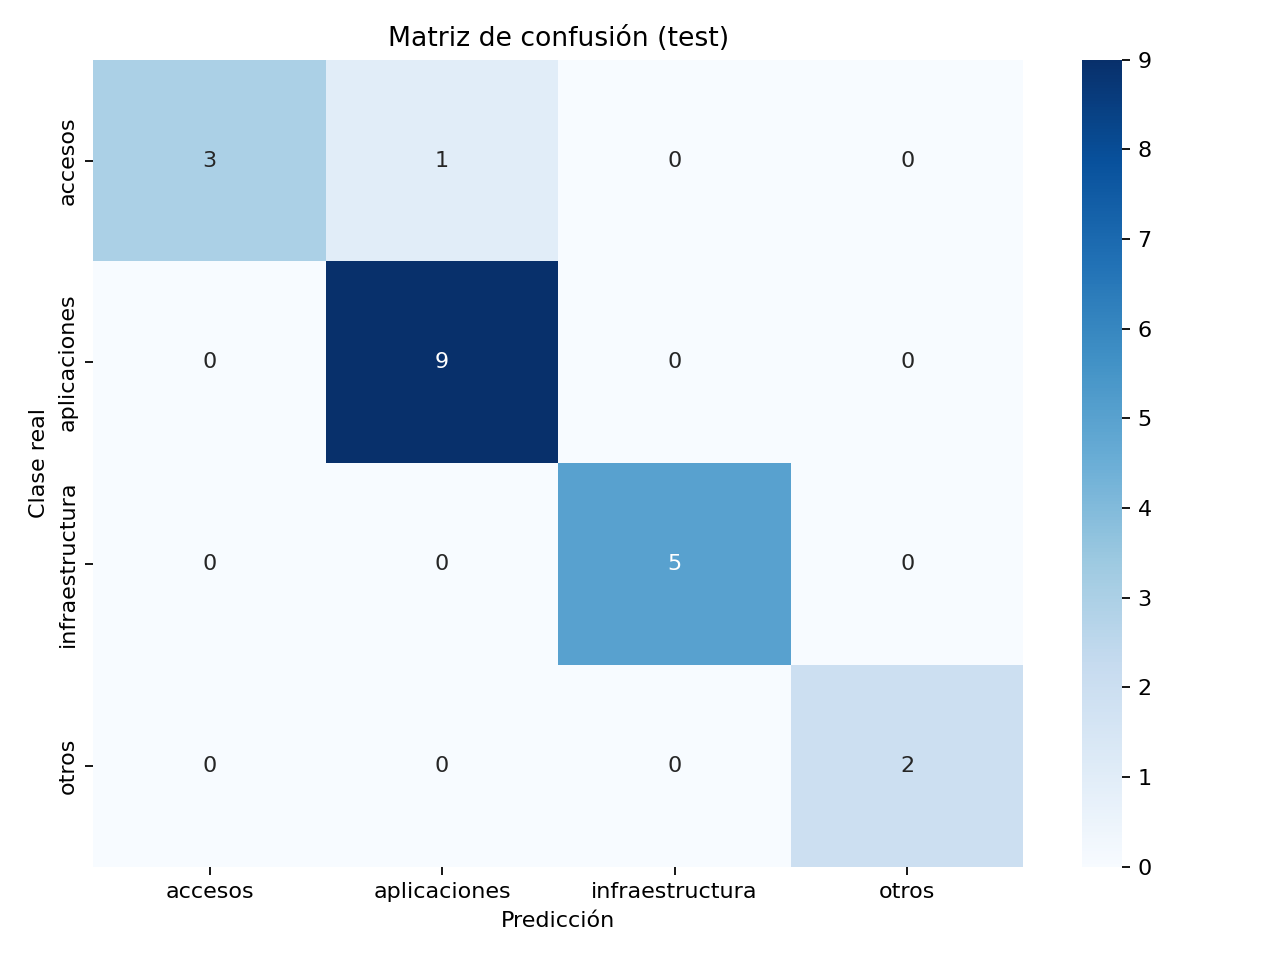

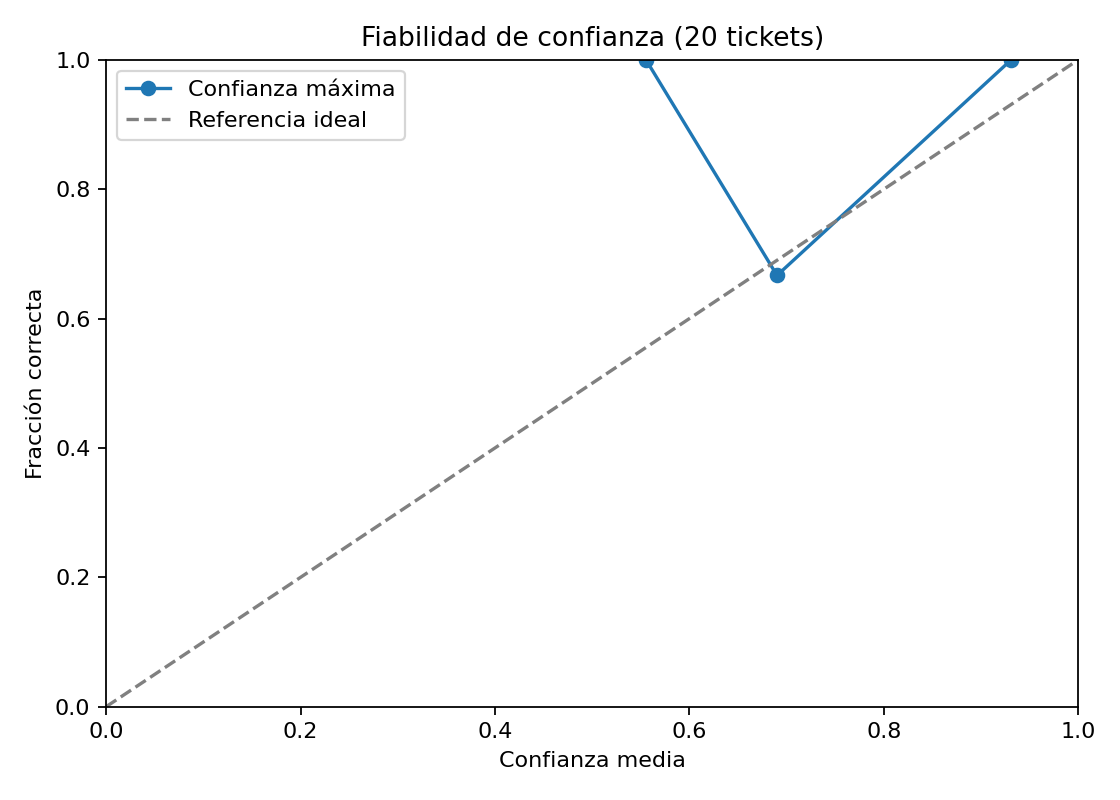

In [3]:
from IPython.display import Image, display
display(Image(filename=str(ROOT / "documentacion/imagenes/confusion_matrix.png")))
display(Image(filename=str(ROOT / "documentacion/imagenes/confidence_reliability.png")))

In [4]:
errors = pd.read_csv(ROOT / "results/metrics" / metrics["artifact_files"]["errors"])
display(errors)
# Textos disponibles solo en el entorno local; no exportar información sensible.
if not errors.empty:
    idx = int(errors.iloc[0].row_id)
    display(test.loc[[idx], ["titulo", "texto", "clasificacion"]])
print("Brecha train/test:", summary["evaluation_train_f1_macro"] - metrics["f1_macro"])

,row_id,real,predicha,confianza,correcta
0,7,accesos,aplicaciones,0.618586,False


Brecha train/test: 0.048872180451127845


## Comparación actual de las versiones 10, 100, 200 y 300

Los archivos finales no se reentrenan durante esta comprobación. Los resultados
se regeneran con `python -m src.evaluate_versions`: integridad de artefactos,
CV exploratoria cuando la calibración lo permite y 25 predicciones por modelo.
Los 25 no tienen etiquetas revisadas: no producen accuracy/F1 de test.
La CV comparte ajustes seleccionados previamente: no es una evaluación externa.
En 10 correos falta soporte por clase para la calibración en los folds.

,correos,train_f1_macro,cv_f1_macro,cv_accuracy,baseline_cv_f1_macro,test_25_count,test_25_review_count
0,10,0.5,NaN,NaN,NaN,25,22
1,100,1.0,0.920065,0.920000,0.096774,25,2
2,200,1.0,0.944225,0.945000,0.096774,25,1
3,300,1.0,0.954286,0.953333,0.115375,25,2


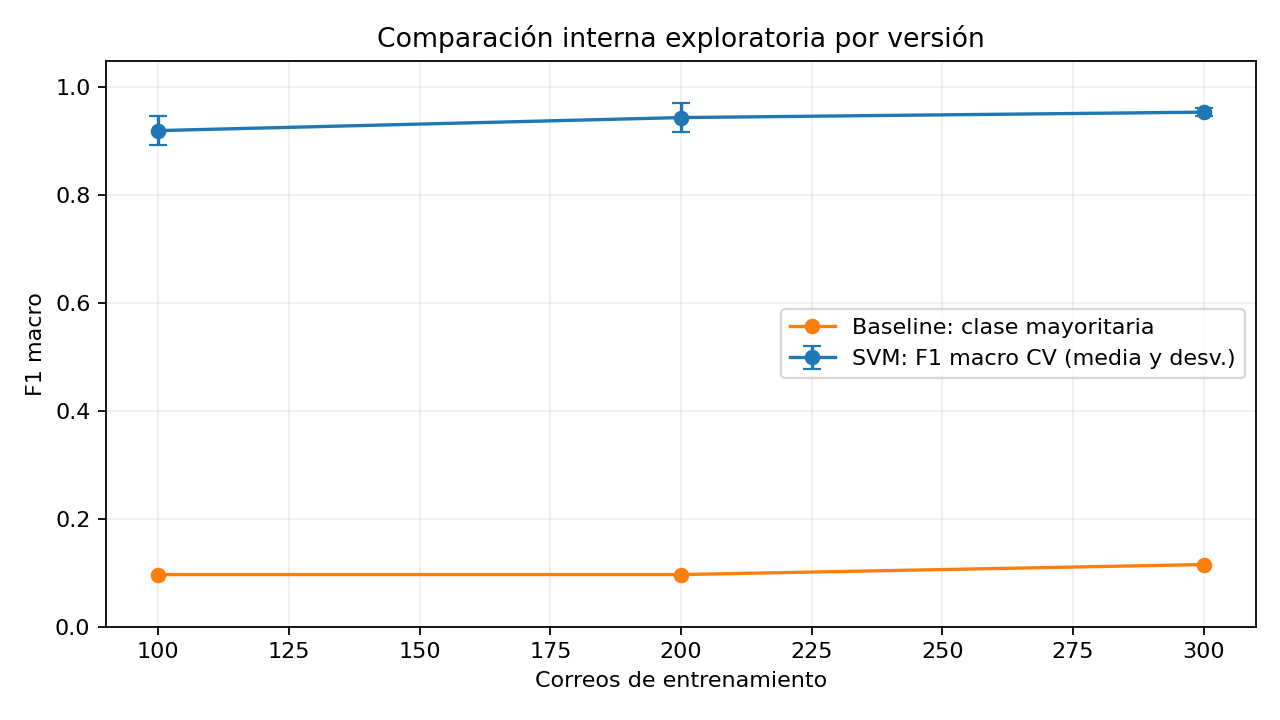

In [5]:
versions = json.loads((ROOT / "results/metrics/version_evaluation.json").read_text(encoding="utf-8"))
assert versions["models_and_datasets_unchanged"]
display(pd.DataFrame(versions["versions"])[[
    "correos", "train_f1_macro", "cv_f1_macro", "cv_accuracy",
    "baseline_cv_f1_macro", "test_25_count", "test_25_review_count"
]])
display(Image(filename=str(ROOT / "documentacion/imagenes/comparacion_modelos_cv.png")))